# ML Data Quality

This notebook checks whether the current Vulkan profile dataset is large and clean enough for meaningful ML. It focuses on join coverage, target availability, class balance, constant columns, and basic sparsity diagnostics.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from src.vulkan_math_data import feature_matrix, load_ml_dataset

sns.set_theme(context="notebook", style="whitegrid")
pd.set_option("display.max_columns", 20)

In [2]:
ml_frame, diagnostics = load_ml_dataset()
X, feature_columns = feature_matrix(ml_frame)
overview = pd.DataFrame([diagnostics]).T.reset_index()
overview.columns = ["metric", "value"]
display(overview)
display(
    ml_frame[
        [
            "report_id",
            "normalized_gpu_name",
            "target__benchmark",
            "target__surrogate_capability_score",
            "label__advanced_rendering_capable",
            "label__high_capability",
        ]
    ]
)
print("Feature matrix shape:", X.shape)
print(
    "Constant columns removed:",
    len(ml_frame.select_dtypes(include="number").columns) - len(feature_columns),
)

,metric,value
0,vulkan_rows,266
1,catalog_matches,469
2,benchmark_matches,507
3,unmatched_catalog_names,"[{'report_id': '16295', 'profile_label': 'Inte..."
4,unmatched_benchmark_names,"[{'report_id': '16295', 'profile_label': 'Inte..."
5,benchmark_target_rows,507
6,raytracing_positive_rows,547
7,advanced_rendering_positive_rows,277
8,high_capability_positive_rows,277


,report_id,normalized_gpu_name,target__benchmark,target__surrogate_capability_score,label__advanced_rendering_capable,label__high_capability
0,10934,rtx 3090,87.4,277.5,0,0
1,10993,rtx 3080,78.9,287.0,0,0
2,10993,rtx 3080,51.8,287.0,0,0
3,11121,rtx 3080,78.9,293.0,0,0
4,11121,rtx 3080,51.8,293.0,0,0
...,...,...,...,...,...,...
542,49144,arc a770,46.1,342.0,0,0
543,49180,rtx 4080,122.0,425.0,1,1
544,49180,rtx 4080,77.1,425.0,1,1
545,49185,rtx 5090,183.0,425.0,1,1


Feature matrix shape: (547, 830)
Constant columns removed: 135


In [3]:
null_summary = ml_frame.isna().sum().sort_values(ascending=False).head(20).reset_index()
null_summary.columns = ["column", "null_count"]
display(null_summary)

label_counts = (
    pd.DataFrame(
        {
            "label__raytracing_capable": ml_frame[
                "label__raytracing_capable"
            ].value_counts(dropna=False),
            "label__advanced_rendering_capable": ml_frame[
                "label__advanced_rendering_capable"
            ].value_counts(dropna=False),
            "label__high_capability": ml_frame["label__high_capability"].value_counts(
                dropna=False
            ),
        }
    )
    .fillna(0)
    .astype(int)
)
display(label_counts)

,column,null_count
0,gpu_name,547
1,driver_info,547
2,driver_name,547
3,prop__VkPhysicalDeviceShaderEnqueuePropertiesA...,546
4,prop__VkPhysicalDeviceShaderEnqueuePropertiesA...,546
5,prop__VkPhysicalDeviceShaderEnqueuePropertiesA...,546
6,prop__VkPhysicalDeviceShaderEnqueuePropertiesA...,546
7,prop__VkPhysicalDeviceShaderEnqueuePropertiesA...,546
8,feat__VkPhysicalDeviceShaderEnqueueFeaturesAMD...,546
9,feat__VkPhysicalDeviceShaderEnqueueFeaturesAMD...,546


,label__raytracing_capable,label__advanced_rendering_capable,label__high_capability
0,0,270,270
1,547,277,277


/tmp/ipykernel_1371/44568982.py:6: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


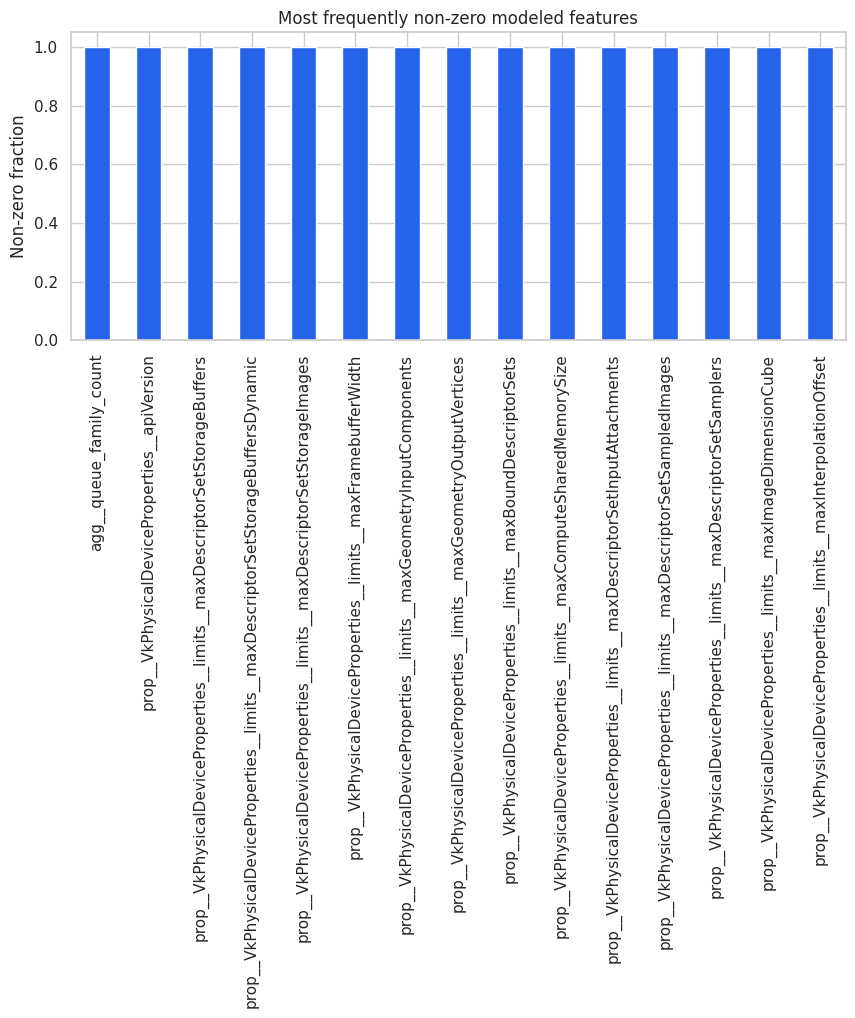

In [4]:
nonzero_fraction = (X != 0).mean().sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 4))
nonzero_fraction.plot.bar(color="#2563eb")
plt.title("Most frequently non-zero modeled features")
plt.ylabel("Non-zero fraction")
plt.tight_layout()
plt.show()